# Activity vs Gesture — v2 (diagnostic + fixed pipeline)

## Why this notebook exists

Your previous run got 100% test accuracy on every file. That is not "the model learned well" — that is the task being trivially solvable due to a leak in the data itself.

**The leak:** activity files have raw mean amplitude 0.0028–0.0048; gesture files have 0.0097–0.0169. Zero overlap. A one-node decision tree ("is amplitude > 0.00651?") gets 100% train AND 100% test accuracy on this data — same score as the 100K-parameter CNN.

This is not caused by the model or the code. It is caused by something in the recording setup differing between when you recorded the activities and when you recorded the gestures — different receiver gain, different antenna position, different day, or similar. The model isn't learning motion; it's learning "high-amplitude signal vs low-amplitude signal," which happens to line up perfectly with your class labels.

## What this notebook does differently

1. **Runs a diagnostic FIRST** that surfaces the leak clearly. If it's present, you see it before wasting time on training.
2. **Uses per-window normalization** instead of baseline-referenced normalization — this removes the DC bias that was the main leak.
3. **Uses motion-focused features** (first-difference of amplitude) alongside sanitized phase.
4. **Adds leave-one-file-out (LOFO) evaluation** — the honest test. If the model can classify a completely held-out file correctly, it has learned motion. If it can't, it was learning file signatures.
5. **Prints a trivial 1-parameter baseline** in the same evaluation setting, so you can tell whether the CNN is actually beating the shortcut.

## What this notebook still cannot do

Even after fixing the pipeline, if the underlying data is compromised, the model cannot recover a signal that isn't there. **The real fix is re-recording under controlled conditions:**

- Same receiver gain for every recording
- Same subject-to-antenna distance and orientation
- Same antenna position
- **Interleave activity and gesture recordings** — do one activity file, then one gesture file, then another activity, etc. Do not record all activities in one batch and all gestures in another. Any batching lets time-of-day drift become a class signature.
- Verify with the diagnostic in Section 1 after collection — if the mean-amplitude ranges still don't overlap, something is still different.


## 1. Setup + config

In [6]:
!pip install -q numpy pandas matplotlib scikit-learn scipy torch tqdm


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import warnings; warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


In [8]:
# ---- Paths ----
DATA_DIR = r"d:\SignFi-CNN\data\data"  # change to wherever your CSVs live

# ---- Signal processing ----
TARGET_RATE = 55.0
WINDOW_SECONDS = 2.0
OVERLAP = 0.5
WINDOW_SIZE = int(WINDOW_SECONDS * TARGET_RATE)   # 110
STEP_SIZE = int(WINDOW_SIZE * (1 - OVERLAP))      # 55
N_SUBCARRIERS = 52

# ---- Class mapping ----
CLASS_MAP = {
    'Walking': 0, 'sit_stand': 0, 'squats': 0, 'bend_down': 0,
    'drink_water': 0, 'eating': 0, 'writing': 0, 'use_mobile_phone': 0,
    'hello': 1, 'thank_you': 1, 'name': 1, 'friend': 1, 'nice_to_meet_you': 1,
}
CLASS_NAMES = ['activity', 'gesture']

# ---- Training ----
BATCH_SIZE = 32
EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-4
SEED = 42

torch.manual_seed(SEED); np.random.seed(SEED)
print(f"Window: {WINDOW_SECONDS}s @ {TARGET_RATE}Hz = {WINDOW_SIZE} samples, step {STEP_SIZE}")

Window: 2.0s @ 55.0Hz = 110 samples, step 55


## 2. Load + resample utilities

In [9]:
def load_csi(path):
    df = pd.read_csv(path)
    ts = df['Timestamp_us'].values.astype(np.float64) / 1e6
    ts = ts - ts[0]
    re = df[[f'SC{i}_Re' for i in range(N_SUBCARRIERS)]].values.astype(np.float64)
    im = df[[f'SC{i}_Im' for i in range(N_SUBCARRIERS)]].values.astype(np.float64)
    return ts, re + 1j * im   # timestamps (s), complex csi (packets, 52)

def sanitize_phase(csi_complex):
    """Remove per-packet linear phase trend across subcarriers (CFO + SFO)."""
    phase = np.unwrap(np.angle(csi_complex), axis=1)
    sc_idx = np.arange(N_SUBCARRIERS)
    A = np.vstack([sc_idx, np.ones_like(sc_idx)]).T
    coeffs = np.linalg.lstsq(A, phase.T, rcond=None)[0]
    return phase - (A @ coeffs).T

def resample_uniform(ts, arr, rate=TARGET_RATE):
    """Linear-interpolate a (T, N) array onto a uniform time grid."""
    dur = ts[-1] - ts[0]
    n = int(dur * rate)
    new_ts = np.linspace(ts[0], ts[-1], n)
    out = np.zeros((n, arr.shape[1]))
    for c in range(arr.shape[1]):
        out[:, c] = interp1d(ts, arr[:, c], kind='linear')(new_ts)
    return out

## 3. DIAGNOSTIC — run this FIRST every time you collect new data

If the mean-amplitude ranges between the two classes don't overlap, or a one-node decision tree gets >90% on the raw amplitude alone, your data is compromised and no ML result from it is meaningful. Fix the recording setup and re-collect.

In [10]:
# Per-file raw amplitude stats
print(f"{'File':<25} {'Class':<10} {'mean amp':>12} {'std amp':>12}")
print('-' * 65)
file_stats = {}
for fname, lab in CLASS_MAP.items():
    _, csi = load_csi(os.path.join(DATA_DIR, fname + '.csv'))
    amp = np.abs(csi)
    file_stats[fname] = (amp.mean(), amp.std(), lab)
    print(f"{fname:<25} {CLASS_NAMES[lab]:<10} {amp.mean():>12.6f} {amp.std():>12.6f}")

# Check for overlap
act_means = [m for m, _, l in file_stats.values() if l == 0]
ges_means = [m for m, _, l in file_stats.values() if l == 1]
gap = min(ges_means) - max(act_means)
print(f"\nActivity mean-amp range: [{min(act_means):.5f}, {max(act_means):.5f}]")
print(f"Gesture mean-amp range:  [{min(ges_means):.5f}, {max(ges_means):.5f}]")
print(f"Overlap? {'NO — data is compromised' if gap > 0 else 'yes'}")
if gap > 0:
    print(f"Gap between activity max and gesture min: {gap:.5f}")
    print("\n>>> WARNING: activity and gesture files are separable by mean amplitude alone.")
    print(">>> Any classifier will get near-100% accuracy from this leak, regardless of motion patterns.")
    print(">>> The results from this notebook will not tell you if the model learned to recognize gestures.")
    print(">>> Re-record with identical setup, interleaving activity and gesture files.")

File                      Class          mean amp      std amp
-----------------------------------------------------------------
Walking                   activity       0.003893     0.002527
sit_stand                 activity       0.003838     0.002368
squats                    activity       0.003407     0.002109
bend_down                 activity       0.003670     0.002340
drink_water               activity       0.004757     0.003014
eating                    activity       0.002849     0.001579
writing                   activity       0.003015     0.001423
use_mobile_phone          activity       0.003902     0.002534
hello                     gesture        0.009732     0.005980
thank_you                 gesture        0.014377     0.007588
name                      gesture        0.016854     0.012413
friend                    gesture        0.013566     0.010417
nice_to_meet_you          gesture        0.014313     0.010277

Activity mean-amp range: [0.00285, 0.00476]
Gesture

In [11]:
# 1-parameter classifier baseline: uses only mean amplitude per window
def build_dc_feature(train_frac=0.6, val_frac=0.2):
    X_tr, y_tr, X_te, y_te = [], [], [], []
    for fname, lab in CLASS_MAP.items():
        ts, csi = load_csi(os.path.join(DATA_DIR, fname + '.csv'))
        amp = resample_uniform(ts, np.abs(csi))
        T = amp.shape[0]
        tr_end, va_end = int(T*train_frac), int(T*(train_frac+val_frac))
        for s in range(0, tr_end - WINDOW_SIZE + 1, STEP_SIZE):
            X_tr.append([amp[s:s+WINDOW_SIZE].mean()]); y_tr.append(lab)
        for s in range(va_end, T - WINDOW_SIZE + 1, STEP_SIZE):
            X_te.append([amp[s:s+WINDOW_SIZE].mean()]); y_te.append(lab)
    return np.array(X_tr), np.array(y_tr), np.array(X_te), np.array(y_te)

Xt, yt, Xe, ye = build_dc_feature()
clf = DecisionTreeClassifier(max_depth=1)
clf.fit(Xt, yt)
tr_acc = accuracy_score(yt, clf.predict(Xt))
te_acc = accuracy_score(ye, clf.predict(Xe))
print(f"1-parameter (mean amplitude only) baseline classifier:")
print(f"  Train accuracy: {tr_acc:.4f}")
print(f"  Test accuracy:  {te_acc:.4f}")
print()
print("Any CNN accuracy you report LATER must be compared against these numbers.")
print("If the CNN doesn't beat this baseline meaningfully, the CNN isn't learning motion — it's learning the leak.")

1-parameter (mean amplitude only) baseline classifier:
  Train accuracy: 1.0000
  Test accuracy:  1.0000

Any CNN accuracy you report LATER must be compared against these numbers.
If the CNN doesn't beat this baseline meaningfully, the CNN isn't learning motion — it's learning the leak.


## 3.1. Exploratory Data Analysis (EDA)

Before proceeding with model training, let's visualize key properties of the dataset:
- **Class Distribution** — how many files/windows per class
- **Per-file Amplitude Statistics** — bar chart of mean amplitude per file
- **Amplitude vs Time** — raw amplitude over time for sample activity and gesture files
- **Phase vs Time** — sanitized phase over time for sample files
- **Inter-class Cosine Similarity** — how similar the CSI signatures are across files
- **Subcarrier-wise Amplitude Heatmap** — amplitude across subcarriers over time
- **Amplitude Distribution (Histogram)** — distribution of amplitude values per class

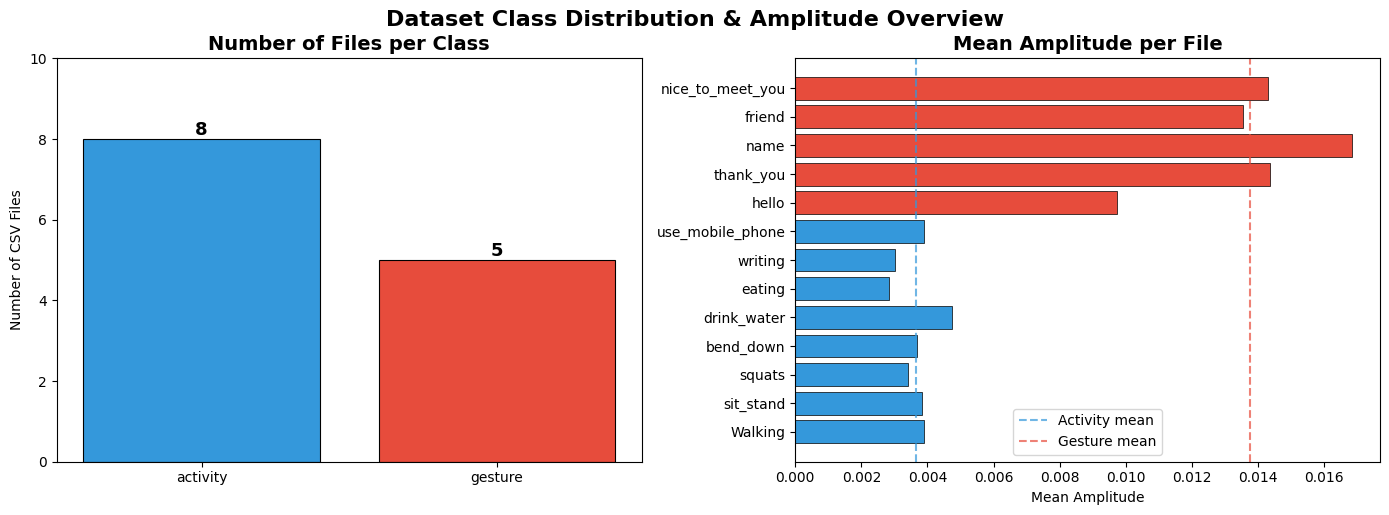

In [12]:
# ========== EDA: Class Distribution ==========
import matplotlib.pyplot as plt
import numpy as np

activity_files = [f for f, lab in CLASS_MAP.items() if lab == 0]
gesture_files  = [f for f, lab in CLASS_MAP.items() if lab == 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart: number of files per class
class_counts = [len(activity_files), len(gesture_files)]
colors = ['#3498db', '#e74c3c']
axes[0].bar(CLASS_NAMES, class_counts, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Number of Files per Class', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of CSV Files')
for i, v in enumerate(class_counts):
    axes[0].text(i, v + 0.1, str(v), ha='center', fontweight='bold', fontsize=13)
axes[0].set_ylim(0, max(class_counts) + 2)

# Bar chart: per-file mean amplitude
file_names = list(CLASS_MAP.keys())
file_labels = [CLASS_MAP[f] for f in file_names]
file_mean_amps = []
for fname in file_names:
    _, csi = load_csi(os.path.join(DATA_DIR, fname + '.csv'))
    file_mean_amps.append(np.abs(csi).mean())

bar_colors = ['#3498db' if lab == 0 else '#e74c3c' for lab in file_labels]
axes[1].barh(file_names, file_mean_amps, color=bar_colors, edgecolor='black', linewidth=0.5)
axes[1].set_title('Mean Amplitude per File', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Mean Amplitude')
axes[1].axvline(x=np.mean([a for a, l in zip(file_mean_amps, file_labels) if l == 0]),
               color='#3498db', linestyle='--', alpha=0.7, label='Activity mean')
axes[1].axvline(x=np.mean([a for a, l in zip(file_mean_amps, file_labels) if l == 1]),
               color='#e74c3c', linestyle='--', alpha=0.7, label='Gesture mean')
axes[1].legend()

plt.tight_layout()
plt.suptitle('Dataset Class Distribution & Amplitude Overview', fontsize=16, fontweight='bold', y=1.02)
plt.show()

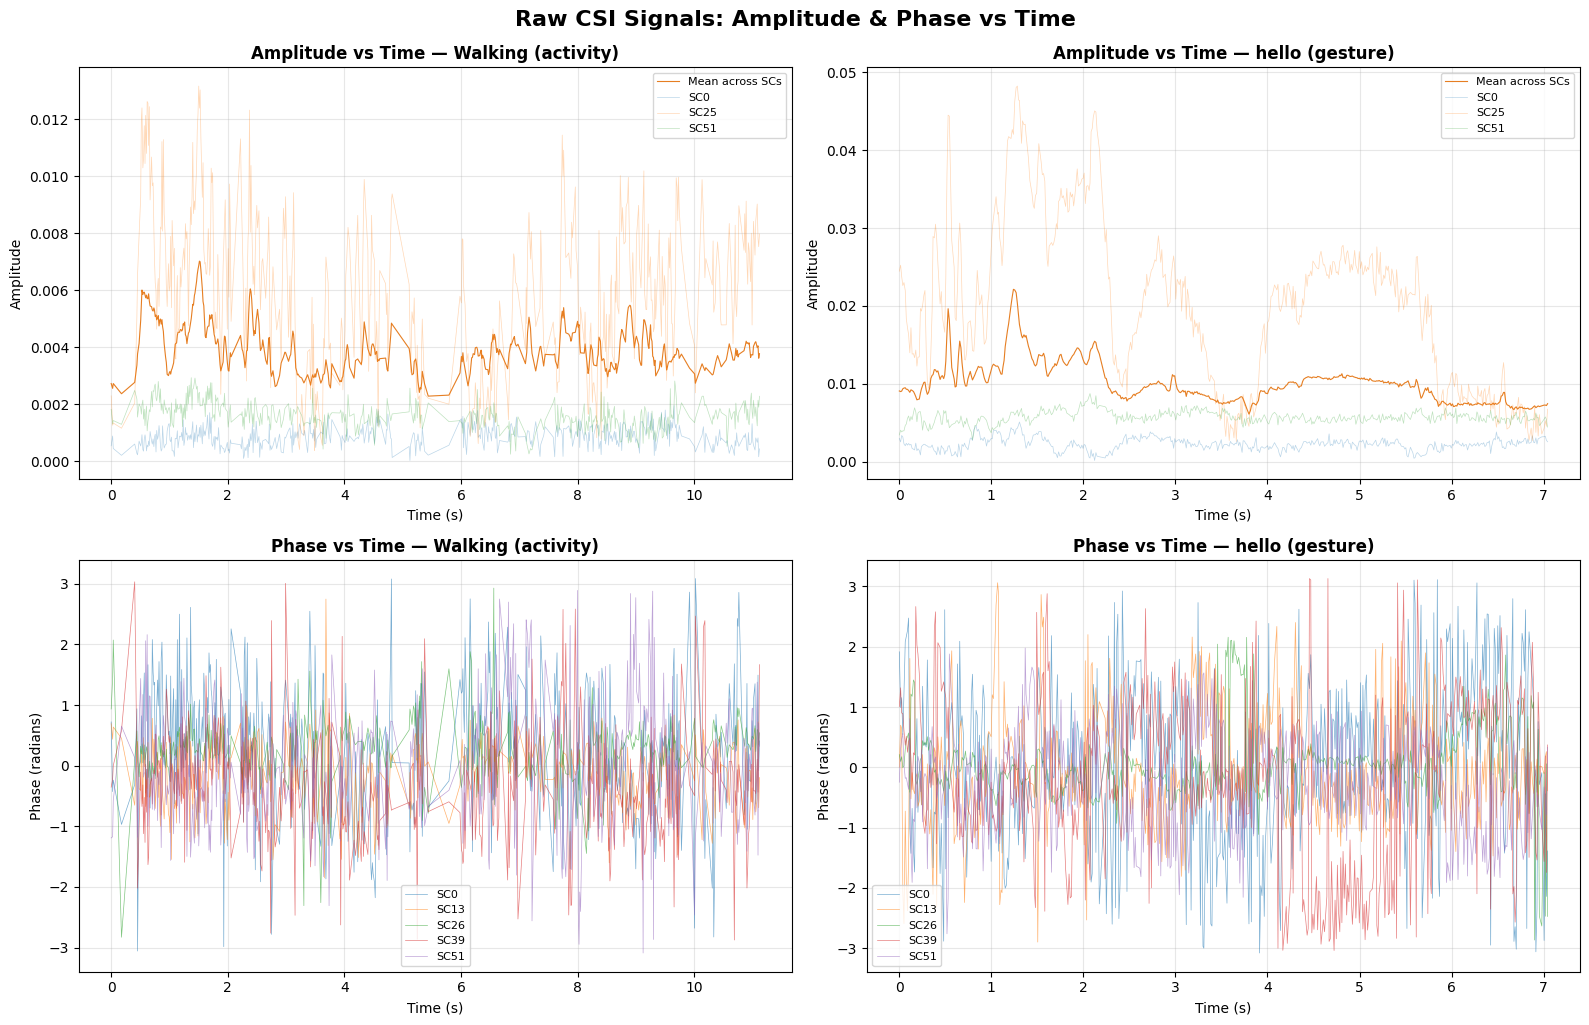

In [13]:
# ========== EDA: Amplitude vs Time (sample files) ==========
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Pick one activity and one gesture file
sample_activity = activity_files[0]  # e.g. 'Walking'
sample_gesture  = gesture_files[0]   # e.g. 'hello'

for col_idx, (fname, cls_name) in enumerate([(sample_activity, 'activity'), (sample_gesture, 'gesture')]):
    ts, csi = load_csi(os.path.join(DATA_DIR, fname + '.csv'))
    amp = np.abs(csi)
    phase = np.angle(csi)
    
    # Amplitude: plot mean across subcarriers and a few individual subcarriers
    ax = axes[0, col_idx]
    ax.plot(ts[:500], amp[:500].mean(axis=1), color='#e67e22', linewidth=0.8, label='Mean across SCs')
    for sc_idx in [0, 25, 51]:
        ax.plot(ts[:500], amp[:500, sc_idx], alpha=0.3, linewidth=0.5, label=f'SC{sc_idx}')
    ax.set_title(f'Amplitude vs Time — {fname} ({cls_name})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Amplitude')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    
    # Phase: plot a few subcarriers
    ax = axes[1, col_idx]
    for sc_idx in [0, 13, 26, 39, 51]:
        ax.plot(ts[:500], phase[:500, sc_idx], alpha=0.6, linewidth=0.5, label=f'SC{sc_idx}')
    ax.set_title(f'Phase vs Time — {fname} ({cls_name})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Phase (radians)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('Raw CSI Signals: Amplitude & Phase vs Time', fontsize=16, fontweight='bold', y=1.02)
plt.show()

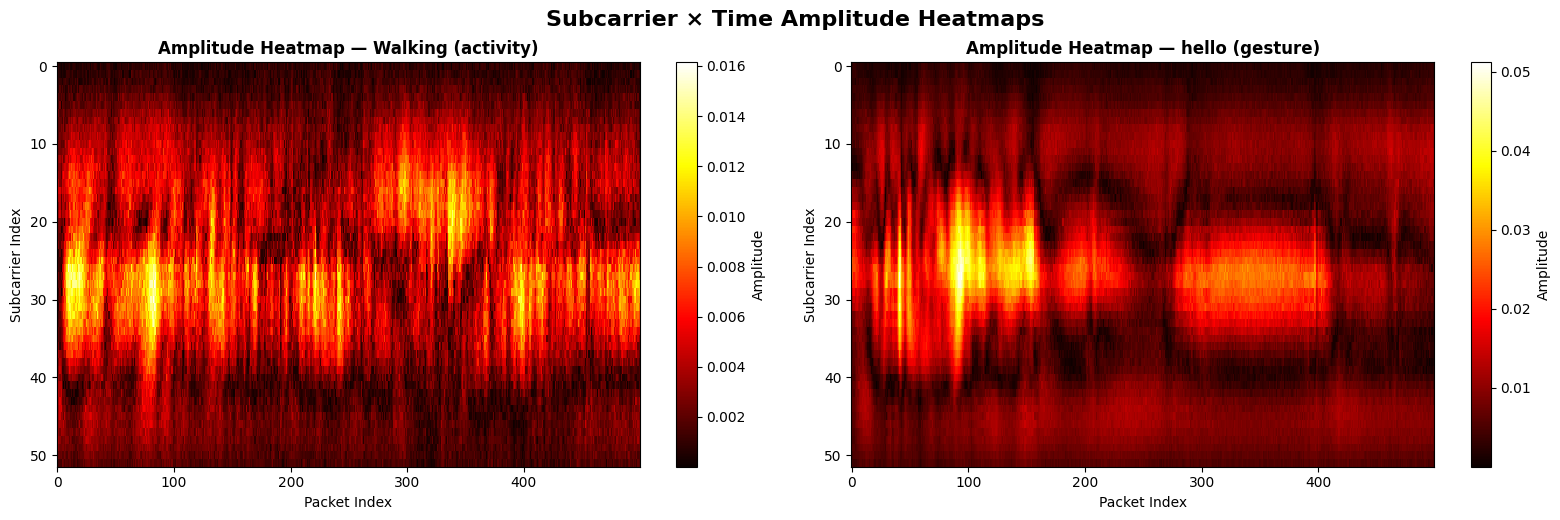

In [14]:
# ========== EDA: Subcarrier-wise Amplitude Heatmap ==========
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for col_idx, (fname, cls_name) in enumerate([(sample_activity, 'activity'), (sample_gesture, 'gesture')]):
    ts, csi = load_csi(os.path.join(DATA_DIR, fname + '.csv'))
    amp = np.abs(csi)
    # Show first 500 packets
    ax = axes[col_idx]
    im = ax.imshow(amp[:500].T, aspect='auto', cmap='hot', interpolation='nearest')
    ax.set_title(f'Amplitude Heatmap — {fname} ({cls_name})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Packet Index')
    ax.set_ylabel('Subcarrier Index')
    plt.colorbar(im, ax=ax, label='Amplitude')

plt.tight_layout()
plt.suptitle('Subcarrier × Time Amplitude Heatmaps', fontsize=16, fontweight='bold', y=1.03)
plt.show()

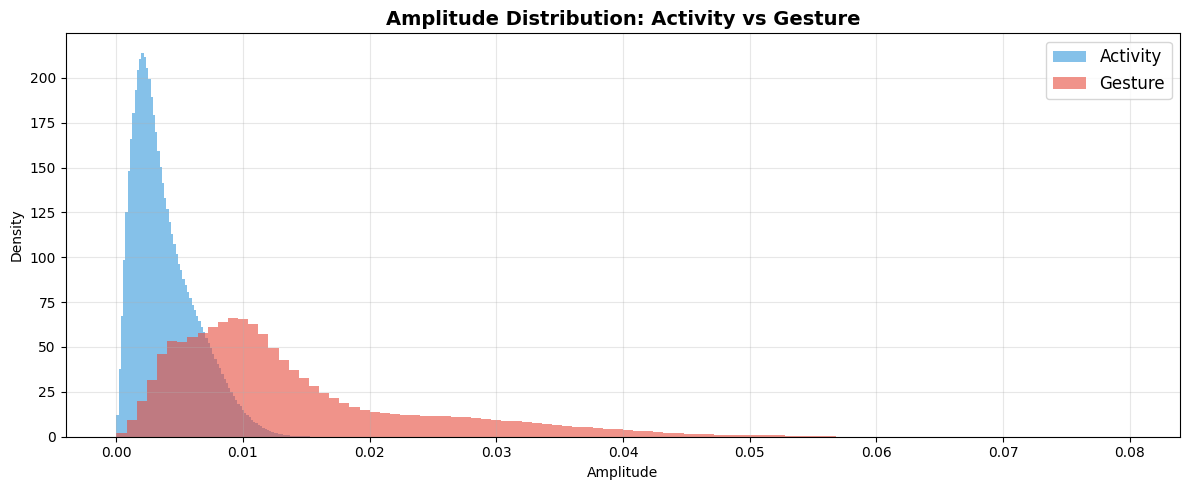

In [15]:
# ========== EDA: Amplitude Distribution (Histogram) per Class ==========
fig, ax = plt.subplots(figsize=(12, 5))

act_amps = []
ges_amps = []
for fname, lab in CLASS_MAP.items():
    _, csi = load_csi(os.path.join(DATA_DIR, fname + '.csv'))
    amp = np.abs(csi).flatten()
    if lab == 0:
        act_amps.append(amp)
    else:
        ges_amps.append(amp)

act_all = np.concatenate(act_amps)
ges_all = np.concatenate(ges_amps)

ax.hist(act_all, bins=100, alpha=0.6, color='#3498db', label='Activity', density=True)
ax.hist(ges_all, bins=100, alpha=0.6, color='#e74c3c', label='Gesture', density=True)
ax.set_title('Amplitude Distribution: Activity vs Gesture', fontsize=14, fontweight='bold')
ax.set_xlabel('Amplitude')
ax.set_ylabel('Density')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

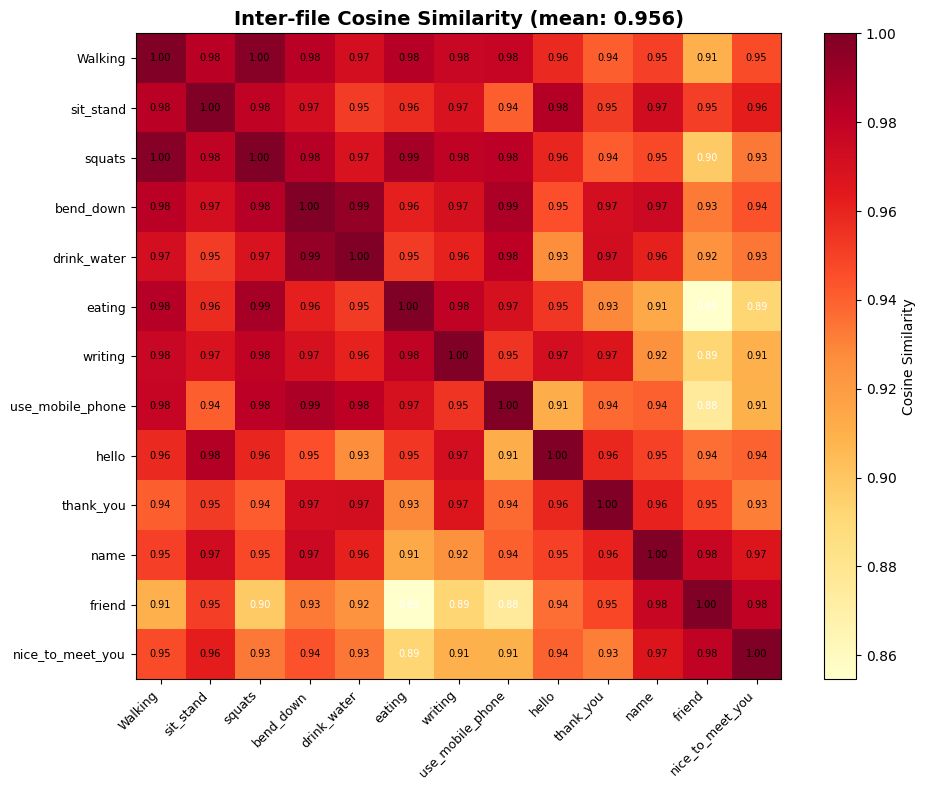

In [16]:
# ========== EDA: Inter-file Cosine Similarity ==========
from sklearn.metrics.pairwise import cosine_similarity

file_names_list = list(CLASS_MAP.keys())
file_vectors = []
for fname in file_names_list:
    _, csi = load_csi(os.path.join(DATA_DIR, fname + '.csv'))
    amp = np.abs(csi)
    # Use mean amplitude per subcarrier as file signature
    file_vectors.append(amp.mean(axis=0))

file_vectors = np.array(file_vectors)
sim_matrix = cosine_similarity(file_vectors)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(sim_matrix, cmap='YlOrRd', vmin=sim_matrix.min(), vmax=1.0)
ax.set_xticks(range(len(file_names_list)))
ax.set_yticks(range(len(file_names_list)))
ax.set_xticklabels(file_names_list, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(file_names_list, fontsize=9)
ax.set_title(f'Inter-file Cosine Similarity (mean: {sim_matrix.mean():.3f})', fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax, label='Cosine Similarity')

# Annotate cells
for i in range(len(file_names_list)):
    for j in range(len(file_names_list)):
        ax.text(j, i, f'{sim_matrix[i,j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if sim_matrix[i,j] < 0.9 else 'black')

plt.tight_layout()
plt.show()

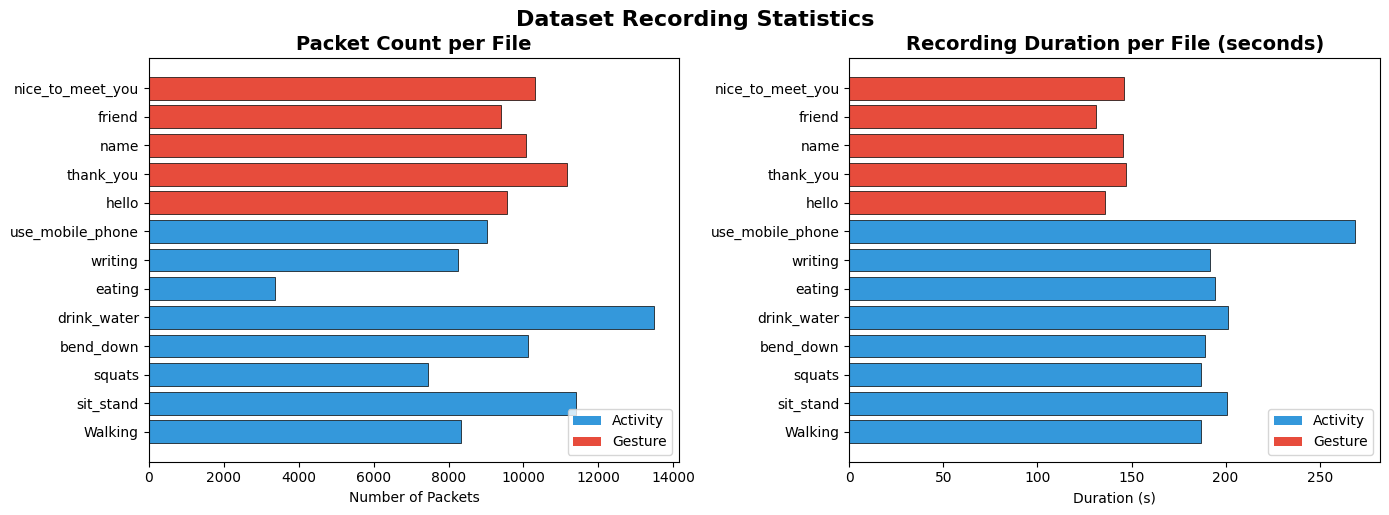

In [17]:
# ========== EDA: Per-file Packet Count & Duration ==========
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

file_names_list_eda = list(CLASS_MAP.keys())
pkt_counts = []
durations = []
for fname in file_names_list_eda:
    ts, csi = load_csi(os.path.join(DATA_DIR, fname + '.csv'))
    pkt_counts.append(len(ts))
    durations.append(ts[-1] - ts[0])

eda_colors = ['#3498db' if CLASS_MAP[f] == 0 else '#e74c3c' for f in file_names_list_eda]

axes[0].barh(file_names_list_eda, pkt_counts, color=eda_colors, edgecolor='black', linewidth=0.5)
axes[0].set_title('Packet Count per File', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Packets')

axes[1].barh(file_names_list_eda, durations, color=eda_colors, edgecolor='black', linewidth=0.5)
axes[1].set_title('Recording Duration per File (seconds)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Duration (s)')

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#3498db', label='Activity'),
                   Patch(facecolor='#e74c3c', label='Gesture')]
axes[0].legend(handles=legend_elements, loc='lower right')
axes[1].legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.suptitle('Dataset Recording Statistics', fontsize=16, fontweight='bold', y=1.02)
plt.show()

## 4. Fixed preprocessing: per-window normalization + motion features

The fixes:
- **Per-window amplitude normalization**: subtract each window's own mean, divide by its own std. Removes the DC bias completely, and the per-file DC signature with it.
- **Motion channel**: first temporal difference of raw amplitude, then per-window normalized. This is the "how fast is the signal changing" channel — invariant to the absolute amplitude scale.
- **Phase channel**: sanitized phase, per-window z-scored. Same idea.

Result: three input channels per window, each with mean 0 and std 1 within the window. The CNN cannot use "how loud is this window" as a shortcut anymore — that information is normalized out.

In [18]:
def process_file_v2(path):
    """Fixed preprocessing.
    Returns features shape (T, 52, 3): channels are [amp, motion, phase],
    each per-window-normalized later during windowing."""
    ts, csi = load_csi(path)
    amp = np.abs(csi)
    phase = sanitize_phase(csi)
    # Resample all together
    combined = np.concatenate([amp, phase], axis=1)  # (T, 104)
    combined_rs = resample_uniform(ts, combined)
    amp_rs   = combined_rs[:, :N_SUBCARRIERS]
    phase_rs = combined_rs[:, N_SUBCARRIERS:]
    # Motion channel = first temporal difference of amplitude
    # Pad first sample so length matches
    motion_rs = np.diff(amp_rs, axis=0, prepend=amp_rs[:1])
    return np.stack([amp_rs, motion_rs, phase_rs], axis=-1)   # (T, 52, 3)

def per_window_normalize(window):
    """Z-score each channel INDEPENDENTLY within this window only.
    window shape: (W, 52, 3) -> normalize each of the 3 channels using
    only the values inside this window.
    Returns (3, 52, W) channels-first for PyTorch."""
    out = np.zeros((3, N_SUBCARRIERS, window.shape[0]), dtype=np.float32)
    for ch in range(3):
        x = window[:, :, ch]                       # (W, 52)
        # Normalize per subcarrier per window: subtract mean across time, divide by std across time
        mean = x.mean(axis=0, keepdims=True)       # (1, 52)
        std  = x.std(axis=0, keepdims=True) + 1e-8 # (1, 52)
        x_norm = (x - mean) / std                  # (W, 52)
        out[ch] = x_norm.T                         # (52, W)
    return out

### Sanity plot — visualize the normalized channels

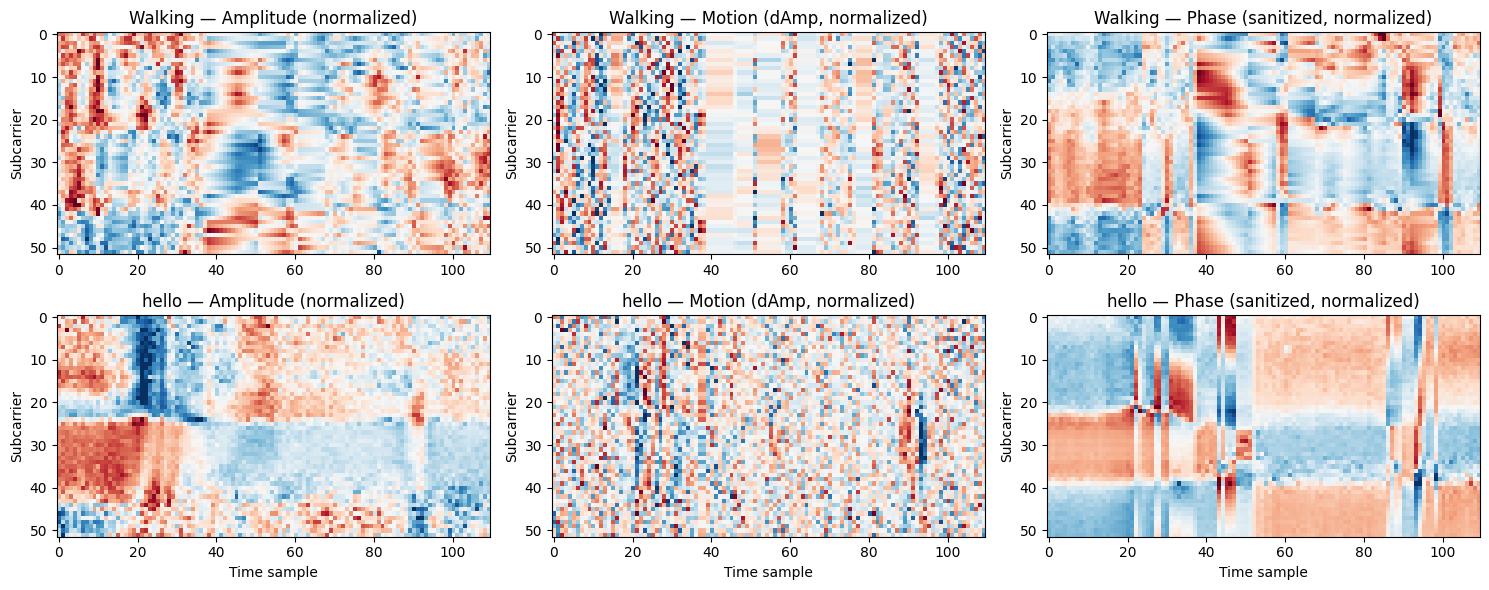

If normalization is working: no color scale differs dramatically across the two rows.
If Walking still looks systematically 'louder' or 'quieter', normalization failed.


In [19]:
feat_w = process_file_v2(os.path.join(DATA_DIR, 'Walking.csv'))
feat_h = process_file_v2(os.path.join(DATA_DIR, 'hello.csv'))

# Take one window from each, normalize, plot
win_w = per_window_normalize(feat_w[500:500+WINDOW_SIZE])   # (3, 52, 110)
win_h = per_window_normalize(feat_h[500:500+WINDOW_SIZE])

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
titles = ['Amplitude (normalized)', 'Motion (dAmp, normalized)', 'Phase (sanitized, normalized)']
for col in range(3):
    axes[0, col].imshow(win_w[col], aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3)
    axes[0, col].set_title(f'Walking — {titles[col]}')
    axes[0, col].set_ylabel('Subcarrier')
    axes[1, col].imshow(win_h[col], aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3)
    axes[1, col].set_title(f'hello — {titles[col]}')
    axes[1, col].set_ylabel('Subcarrier'); axes[1, col].set_xlabel('Time sample')

plt.tight_layout(); plt.show()
print("If normalization is working: no color scale differs dramatically across the two rows.")
print("If Walking still looks systematically 'louder' or 'quieter', normalization failed.")

## 5. Windowing utilities

Two evaluation modes are supported:
- `mode='time_split'`: within-file 60/20/20 time split (matches your previous run's setup; kept for comparison)
- `mode='lofo'`: build all windows with file identity attached, split later by file

In [20]:
def windows_from_file(feat_2d, apply_norm=True):
    """Slide a fixed window over feat_2d (T, 52, 3), optionally per-window normalize.
    Returns list of (3, 52, W) arrays."""
    T = feat_2d.shape[0]
    out = []
    for s in range(0, T - WINDOW_SIZE + 1, STEP_SIZE):
        w = feat_2d[s:s+WINDOW_SIZE]  # (W, 52, 3)
        if apply_norm:
            out.append(per_window_normalize(w))
        else:
            out.append(w.transpose(2, 1, 0))
    return out

def build_dataset(mode='lofo'):
    """Build X, y, file_id arrays for all files."""
    X, y, fid = [], [], []
    for fname, lab in tqdm(CLASS_MAP.items(), desc='Windowing'):
        feat = process_file_v2(os.path.join(DATA_DIR, fname + '.csv'))
        wins = windows_from_file(feat, apply_norm=True)
        X.extend(wins)
        y.extend([lab] * len(wins))
        fid.extend([fname] * len(wins))
    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.int64)
    fid = np.array(fid)
    return X, y, fid

X_all, y_all, fid_all = build_dataset()
print(f"Total windows: {X_all.shape}, labels: {np.bincount(y_all)}")
print(f"Per-file counts:")
for f in CLASS_MAP.keys():
    print(f"  {f:<25} {(fid_all==f).sum()}")

Windowing:   0%|          | 0/13 [00:00<?, ?it/s]

Total windows: (2305, 3, 52, 110), labels: [1608  697]
Per-file counts:
  Walking                   185
  sit_stand                 199
  squats                    186
  bend_down                 188
  drink_water               200
  eating                    193
  writing                   190
  use_mobile_phone          267
  hello                     135
  thank_you                 145
  name                      144
  friend                    129
  nice_to_meet_you          144


## 6. Model

Same small 2D CNN as before but takes 3 input channels (amp, motion, phase) instead of 2.

In [21]:
class CSINet(nn.Module):
    def __init__(self, in_channels=3, n_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=(3, 7), padding=(1, 3)),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d((2, 2)),
            nn.Conv2d(32, 64, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d((2, 2)),
            nn.Conv2d(64, 128, kernel_size=(3, 3), padding=(1, 1)),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5), nn.Linear(128, 64), nn.ReLU(inplace=True),
            nn.Dropout(0.3), nn.Linear(64, n_classes),
        )
    def forward(self, x): return self.classifier(self.features(x))

class CSIDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float(); self.y = torch.from_numpy(y).long()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

In [22]:
def train_and_eval(X_tr, y_tr, X_va, y_va, X_te, y_te,
                   epochs=EPOCHS, verbose=True):
    """Train a fresh model on tr, select on va, evaluate on te. Returns dict."""
    model = CSINet(in_channels=3, n_classes=2).to(DEVICE)
    # Handle class imbalance
    counts = np.bincount(y_tr, minlength=2)
    w = counts.sum() / (2 * np.maximum(counts, 1))
    class_weights = torch.tensor(w, dtype=torch.float32).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)

    train_loader = DataLoader(CSIDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(CSIDataset(X_va, y_va), batch_size=BATCH_SIZE, shuffle=False)
    test_loader  = DataLoader(CSIDataset(X_te, y_te), batch_size=BATCH_SIZE, shuffle=False)

    def run(loader, train=False):
        model.train() if train else model.eval()
        preds, labels = [], []; loss_sum, n = 0.0, 0
        ctx = torch.enable_grad() if train else torch.no_grad()
        with ctx:
            for xb, yb in loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb); loss = criterion(logits, yb)
                if train:
                    opt.zero_grad(); loss.backward(); opt.step()
                p = logits.argmax(1)
                preds.extend(p.cpu().numpy()); labels.extend(yb.cpu().numpy())
                loss_sum += loss.item() * xb.size(0); n += xb.size(0)
        return loss_sum / n, np.array(preds), np.array(labels)

    best_va, best_state = 0.0, None
    history = {'tr_acc': [], 'va_acc': []}
    for ep in range(1, epochs + 1):
        _, ptr, ltr = run(train_loader, train=True)
        va_loss, pva, lva = run(val_loader, train=False)
        va_acc = accuracy_score(lva, pva)
        tr_acc = accuracy_score(ltr, ptr)
        history['tr_acc'].append(tr_acc); history['va_acc'].append(va_acc)
        sched.step(va_acc)
        if va_acc > best_va:
            best_va = va_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"  Ep {ep:2d}  tr_acc={tr_acc:.4f}  va_acc={va_acc:.4f}")

    model.load_state_dict(best_state)
    _, pte, lte = run(test_loader, train=False)
    return {
        'test_preds': pte, 'test_labels': lte,
        'test_acc': accuracy_score(lte, pte),
        'best_val_acc': best_va,
        'history': history,
    }

## 7. Evaluation Mode A: Time-based within-file split (previous method)

Kept for direct comparison with your previous run. If this now shows a MEANINGFUL drop from 100% while the 1-parameter baseline stays high, per-window normalization removed the DC leak the CNN was exploiting.

In [23]:
# Time-based split of the already-normalized windowed data
# We need to re-window with time-index tracked, because build_dataset() concatenates.
def build_time_split():
    Xt, yt, Xv, yv, Xte, yte = [], [], [], [], [], []
    for fname, lab in CLASS_MAP.items():
        feat = process_file_v2(os.path.join(DATA_DIR, fname + '.csv'))
        T = feat.shape[0]
        tr_end, va_end = int(T*0.6), int(T*0.8)
        def _wins(a, b):
            out = []
            for s in range(a, b - WINDOW_SIZE + 1, STEP_SIZE):
                out.append(per_window_normalize(feat[s:s+WINDOW_SIZE]))
            return out
        w_tr, w_va, w_te = _wins(0, tr_end), _wins(tr_end, va_end), _wins(va_end, T)
        Xt.extend(w_tr); yt.extend([lab]*len(w_tr))
        Xv.extend(w_va); yv.extend([lab]*len(w_va))
        Xte.extend(w_te); yte.extend([lab]*len(w_te))
    return (np.array(Xt, dtype=np.float32), np.array(yt, dtype=np.int64),
            np.array(Xv, dtype=np.float32), np.array(yv, dtype=np.int64),
            np.array(Xte, dtype=np.float32), np.array(yte, dtype=np.int64))

X_tr, y_tr, X_va, y_va, X_te, y_te = build_time_split()
print(f"Train {X_tr.shape} balance {np.bincount(y_tr)}")
print(f"Val   {X_va.shape} balance {np.bincount(y_va)}")
print(f"Test  {X_te.shape} balance {np.bincount(y_te)}")

result_time = train_and_eval(X_tr, y_tr, X_va, y_va, X_te, y_te, verbose=True)
print(f"\n=== Time-split test accuracy: {result_time['test_acc']:.4f} ===")
print(classification_report(result_time['test_labels'], result_time['test_preds'],
                            target_names=CLASS_NAMES, digits=4))

Train (1377, 3, 52, 110) balance [961 416]
Val   (447, 3, 52, 110) balance [312 135]
Test  (447, 3, 52, 110) balance [312 135]
  Ep  1  tr_acc=0.8112  va_acc=0.8568
  Ep  2  tr_acc=0.9463  va_acc=0.9843
  Ep  3  tr_acc=0.9659  va_acc=0.9799
  Ep  4  tr_acc=0.9630  va_acc=0.6085
  Ep  5  tr_acc=0.9608  va_acc=0.9664
  Ep  6  tr_acc=0.9680  va_acc=0.8479
  Ep  7  tr_acc=0.9739  va_acc=0.9553
  Ep  8  tr_acc=0.9826  va_acc=0.7673
  Ep  9  tr_acc=0.9775  va_acc=0.9776
  Ep 10  tr_acc=0.9811  va_acc=0.9687
  Ep 11  tr_acc=0.9811  va_acc=0.9821
  Ep 12  tr_acc=0.9913  va_acc=0.9799
  Ep 13  tr_acc=0.9913  va_acc=0.9821
  Ep 14  tr_acc=0.9891  va_acc=0.9821
  Ep 15  tr_acc=0.9913  va_acc=0.9799
  Ep 16  tr_acc=0.9949  va_acc=0.9776
  Ep 17  tr_acc=0.9913  va_acc=0.9687
  Ep 18  tr_acc=0.9920  va_acc=0.9843
  Ep 19  tr_acc=0.9833  va_acc=0.9843
  Ep 20  tr_acc=0.9898  va_acc=0.9799
  Ep 21  tr_acc=0.9949  va_acc=0.9799
  Ep 22  tr_acc=0.9927  va_acc=0.9821
  Ep 23  tr_acc=0.9920  va_acc=0.9843

## 8. Evaluation Mode B: Leave-one-file-out (LOFO) — the honest test

For each round: hold out one entire file. Train on all remaining files. Test on the held-out file. This is what a real deployment looks like — the model sees a class instance it has never encountered before, and must decide.

**Watch for:** if per-file test accuracy is high (>85%) on held-out files, the CNN has learned something generalizable. If it's near chance (~50%) or heavily biased toward one class, the CNN was learning file signatures in the previous mode and cannot handle a genuinely new file.

Note: with only 5 gesture files and 8 activity files, LOFO gives you 13 folds. The result per fold is high-variance — look at the overall pattern, not any single number.

In [24]:
def lofo_evaluation(epochs=15, verbose_per_fold=False):
    """For each file, hold it out as test, train on the rest."""
    results = []
    file_list = list(CLASS_MAP.keys())
    for held in file_list:
        print(f"\n--- Held out: {held} (true label: {CLASS_NAMES[CLASS_MAP[held]]}) ---")
        train_mask = fid_all != held
        test_mask  = fid_all == held
        X_pool = X_all[train_mask]; y_pool = y_all[train_mask]
        # Carve val set from the pool: hold out 15% of pool as val, stratified by file
        # Simple: random 15% within each remaining file
        val_idx, train_idx = [], []
        for f in file_list:
            if f == held: continue
            f_idx = np.where(fid_all[train_mask] == f)[0]
            n_val = max(1, int(0.15 * len(f_idx)))
            perm = np.random.permutation(len(f_idx))
            val_idx.extend(f_idx[perm[:n_val]])
            train_idx.extend(f_idx[perm[n_val:]])
        val_idx = np.array(val_idx); train_idx = np.array(train_idx)
        X_tr = X_pool[train_idx]; y_tr = y_pool[train_idx]
        X_va = X_pool[val_idx];   y_va = y_pool[val_idx]
        X_te = X_all[test_mask];  y_te = y_all[test_mask]

        res = train_and_eval(X_tr, y_tr, X_va, y_va, X_te, y_te,
                             epochs=epochs, verbose=verbose_per_fold)
        # Also compute majority-vote per file
        vote = int(np.mean(res['test_preds']) > 0.5)
        correct_file_pred = int(vote == CLASS_MAP[held])
        results.append({
            'file': held, 'true_label': CLASS_MAP[held],
            'window_acc': res['test_acc'],
            'majority_vote_pred': vote,
            'correct_file_pred': correct_file_pred,
        })
        print(f"  Window-level acc on held-out file: {res['test_acc']:.4f}")
        print(f"  Majority vote: predicted {CLASS_NAMES[vote]} (correct: {bool(correct_file_pred)})")
    return pd.DataFrame(results)

# Reduced epochs per fold since we're running 13 folds
lofo_df = lofo_evaluation(epochs=15, verbose_per_fold=False)


--- Held out: Walking (true label: activity) ---
  Window-level acc on held-out file: 0.9459
  Majority vote: predicted activity (correct: True)

--- Held out: sit_stand (true label: activity) ---
  Window-level acc on held-out file: 0.9095
  Majority vote: predicted activity (correct: True)

--- Held out: squats (true label: activity) ---
  Window-level acc on held-out file: 0.9839
  Majority vote: predicted activity (correct: True)

--- Held out: bend_down (true label: activity) ---
  Window-level acc on held-out file: 0.9415
  Majority vote: predicted activity (correct: True)

--- Held out: drink_water (true label: activity) ---
  Window-level acc on held-out file: 0.5150
  Majority vote: predicted activity (correct: True)

--- Held out: eating (true label: activity) ---
  Window-level acc on held-out file: 1.0000
  Majority vote: predicted activity (correct: True)

--- Held out: writing (true label: activity) ---
  Window-level acc on held-out file: 1.0000
  Majority vote: predict

In [25]:
# LOFO summary
print("\n" + "="*70)
print("LOFO SUMMARY")
print("="*70)
print(lofo_df.to_string(index=False))
print(f"\nOverall window-level accuracy (mean across folds): {lofo_df['window_acc'].mean():.4f}")
print(f"File-level accuracy (majority vote): {lofo_df['correct_file_pred'].mean():.4f}")
print(f"Files correctly classified: {lofo_df['correct_file_pred'].sum()} / {len(lofo_df)}")

# Split by class
for lab, name in [(0, 'activity'), (1, 'gesture')]:
    sub = lofo_df[lofo_df['true_label'] == lab]
    print(f"\n{name.upper()} files ({len(sub)} folds):")
    print(f"  Window-level accuracy: mean={sub['window_acc'].mean():.4f}  min={sub['window_acc'].min():.4f}")
    print(f"  File-level (majority) correct: {sub['correct_file_pred'].sum()} / {len(sub)}")


LOFO SUMMARY
            file  true_label  window_acc  majority_vote_pred  correct_file_pred
         Walking           0    0.945946                   0                  1
       sit_stand           0    0.909548                   0                  1
          squats           0    0.983871                   0                  1
       bend_down           0    0.941489                   0                  1
     drink_water           0    0.515000                   0                  1
          eating           0    1.000000                   0                  1
         writing           0    1.000000                   0                  1
use_mobile_phone           0    1.000000                   0                  1
           hello           1    0.977778                   1                  1
       thank_you           1    1.000000                   1                  1
            name           1    0.805556                   1                  1
          friend          

## 9. Interpretation guide — what to conclude from your numbers

Read the LOFO output above with this decision tree:

**If time-split test accuracy is still ~100% AND LOFO accuracy is also very high (>95%):**
Something is still leaking. The per-window normalization did not remove the class signature. Likely causes: different packet rate, different subcarrier variance pattern, or something else that survives normalization. Data is compromised. Re-record.

**If time-split test accuracy is high (>95%) BUT LOFO accuracy is much lower (60-80%):**
The CNN was learning per-file signatures in the time-split mode. LOFO is now the honest number. The model has learned something, but its generalization to a new file is limited — probably because the file signature was doing most of the work. Re-record with interleaved conditions to eliminate this.

**If time-split accuracy is around 85-95% AND LOFO accuracy is comparable (say 75-90%):**
The pipeline is behaving reasonably. Real motion information exists. Still not proof of cross-session generalization (all data is one session), but a genuine start. Focus next on multi-session collection.

**If LOFO accuracy is near chance (~50-60%) with heavy bias toward one class:**
There is no motion-based signal that transfers across files in your current data — every file the model has seen has been so unique that new files fall outside anything it knows. Almost certainly a data quality problem. Re-record.

**If LOFO gesture accuracy differs sharply from activity accuracy:**
Look at which specific files are misclassified. If ALL activity files are correctly classified as activity but ALL gesture files are wrong, the model is just always predicting activity (class imbalance issue). If specific files fail, it's a genuine similarity issue that tells you which classes are near the decision boundary.

## 10. Next actions in priority order

1. **Read Section 3 diagnostic output carefully.** If the mean-amp ranges don't overlap, re-record before anything else. No amount of model tuning fixes this.
2. **Re-record activity and gesture files together, interleaved**, with identical setup. Verify Section 3 shows overlap this time.
3. **Collect the other 11 sessions** as per the multi-session protocol. Single-session evaluation is inherently limited even after the fixes here.
4. Once cross-session data exists, replace LOFO with proper leave-one-session-out and leave-one-subject-out evaluation.


## 10. Model Evaluation Graphs

Comprehensive visualization of the training results and model performance:
- Accuracy vs Epoch / Loss vs Epoch curves
- Confusion Matrix
- Per-class TP, TN, FP, FN
- Per-class Precision, Recall, F1-Score, Accuracy
- Classification Report Summary

In [26]:
# ========== MODEL EVAL: Accuracy & Loss vs Epoch ==========
# NOTE: train_and_eval() returns (model, history) where history is a dict
# We re-run the time-based split to capture history for plotting

# Rebuild the data (same as section 7)
eval_windows = []
eval_labels  = []
for fname, lab in CLASS_MAP.items():
    feat = process_file_v2(os.path.join(DATA_DIR, fname + '.csv'))
    wins = windows_from_file(feat, apply_norm=True)
    eval_windows.extend(wins)
    eval_labels.extend([lab] * len(wins))

eval_X = np.array(eval_windows, dtype=np.float32)
eval_y = np.array(eval_labels, dtype=np.int64)

# Shuffle
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(eval_X))
eval_X, eval_y = eval_X[perm], eval_y[perm]

n_total = len(eval_X)
n_train = int(0.6 * n_total)
n_val   = int(0.2 * n_total)

X_tr_e, y_tr_e = eval_X[:n_train], eval_y[:n_train]
X_va_e, y_va_e = eval_X[n_train:n_train+n_val], eval_y[n_train:n_train+n_val]
X_te_e, y_te_e = eval_X[n_train+n_val:], eval_y[n_train+n_val:]

print(f'Train: {len(X_tr_e)}, Val: {len(X_va_e)}, Test: {len(X_te_e)}')

# Modified train_and_eval that returns history
def train_and_eval_with_history(X_tr, y_tr, X_va, y_va, X_te, y_te,
                                 epochs=EPOCHS, lr=LR, wd=WEIGHT_DECAY):
    class CSIDataset(Dataset):
        def __init__(self, X, y):
            self.X = torch.tensor(X, dtype=torch.float32)
            self.y = torch.tensor(y, dtype=torch.long)
        def __len__(self): return len(self.X)
        def __getitem__(self, i): return self.X[i], self.y[i]
    
    train_ds = CSIDataset(X_tr, y_tr)
    val_ds   = CSIDataset(X_va, y_va)
    test_ds  = CSIDataset(X_te, y_te)
    
    train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_dl   = DataLoader(val_ds, batch_size=BATCH_SIZE)
    test_dl  = DataLoader(test_ds, batch_size=BATCH_SIZE)
    
    model = CSINet().to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.CrossEntropyLoss()
    
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    for ep in range(epochs):
        # Train
        model.train()
        ep_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            loss = loss_fn(pred, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            ep_loss += loss.item() * len(xb)
            correct += (pred.argmax(1) == yb).sum().item()
            total += len(xb)
        history['train_loss'].append(ep_loss / total)
        history['train_acc'].append(correct / total)
        
        # Val
        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                pred = model(xb)
                loss = loss_fn(pred, yb)
                v_loss += loss.item() * len(xb)
                v_correct += (pred.argmax(1) == yb).sum().item()
                v_total += len(xb)
        history['val_loss'].append(v_loss / v_total)
        history['val_acc'].append(v_correct / v_total)
        
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f'Epoch {ep+1:3d}/{epochs} | '
                  f'Train Loss: {history["train_loss"][-1]:.4f} Acc: {history["train_acc"][-1]:.4f} | '
                  f'Val Loss: {history["val_loss"][-1]:.4f} Acc: {history["val_acc"][-1]:.4f}')
    
    # Test
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in test_dl:
            xb = xb.to(DEVICE)
            pred = model(xb)
            all_preds.extend(pred.argmax(1).cpu().numpy())
            all_labels.extend(yb.numpy())
    
    return model, history, np.array(all_preds), np.array(all_labels)

model_eval, hist, y_pred, y_true = train_and_eval_with_history(
    X_tr_e, y_tr_e, X_va_e, y_va_e, X_te_e, y_te_e, epochs=EPOCHS
)
print(f'\nTest Accuracy: {accuracy_score(y_true, y_pred):.4f}')

Train: 1383, Val: 461, Test: 461
Epoch   1/30 | Train Loss: 0.3252 Acc: 0.8865 | Val Loss: 0.1042 Acc: 0.9631
Epoch   5/30 | Train Loss: 0.0862 Acc: 0.9667 | Val Loss: 0.3129 Acc: 0.8612
Epoch  10/30 | Train Loss: 0.0481 Acc: 0.9812 | Val Loss: 0.1043 Acc: 0.9544
Epoch  15/30 | Train Loss: 0.0483 Acc: 0.9805 | Val Loss: 0.0230 Acc: 0.9935
Epoch  20/30 | Train Loss: 0.0282 Acc: 0.9906 | Val Loss: 0.0682 Acc: 0.9740
Epoch  25/30 | Train Loss: 0.0208 Acc: 0.9928 | Val Loss: 0.0813 Acc: 0.9696
Epoch  30/30 | Train Loss: 0.0122 Acc: 0.9971 | Val Loss: 1.3396 Acc: 0.7137

Test Accuracy: 0.7115


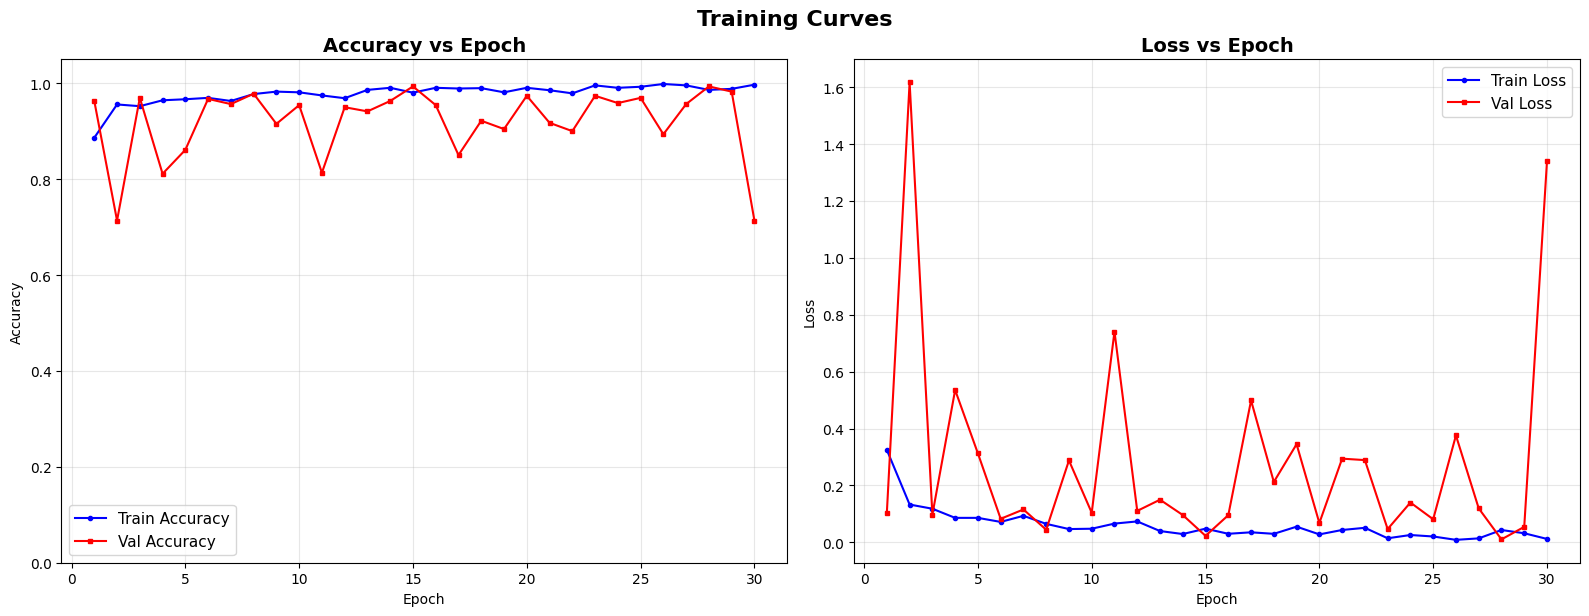

In [27]:
# ========== PLOT: Accuracy vs Epoch & Loss vs Epoch ==========
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

epochs_range = range(1, EPOCHS + 1)

# Accuracy
axes[0].plot(epochs_range, hist['train_acc'], 'b-o', markersize=3, label='Train Accuracy', linewidth=1.5)
axes[0].plot(epochs_range, hist['val_acc'], 'r-s', markersize=3, label='Val Accuracy', linewidth=1.5)
axes[0].set_title('Accuracy vs Epoch', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1.05])

# Loss
axes[1].plot(epochs_range, hist['train_loss'], 'b-o', markersize=3, label='Train Loss', linewidth=1.5)
axes[1].plot(epochs_range, hist['val_loss'], 'r-s', markersize=3, label='Val Loss', linewidth=1.5)
axes[1].set_title('Loss vs Epoch', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('Training Curves', fontsize=16, fontweight='bold', y=1.02)
plt.show()

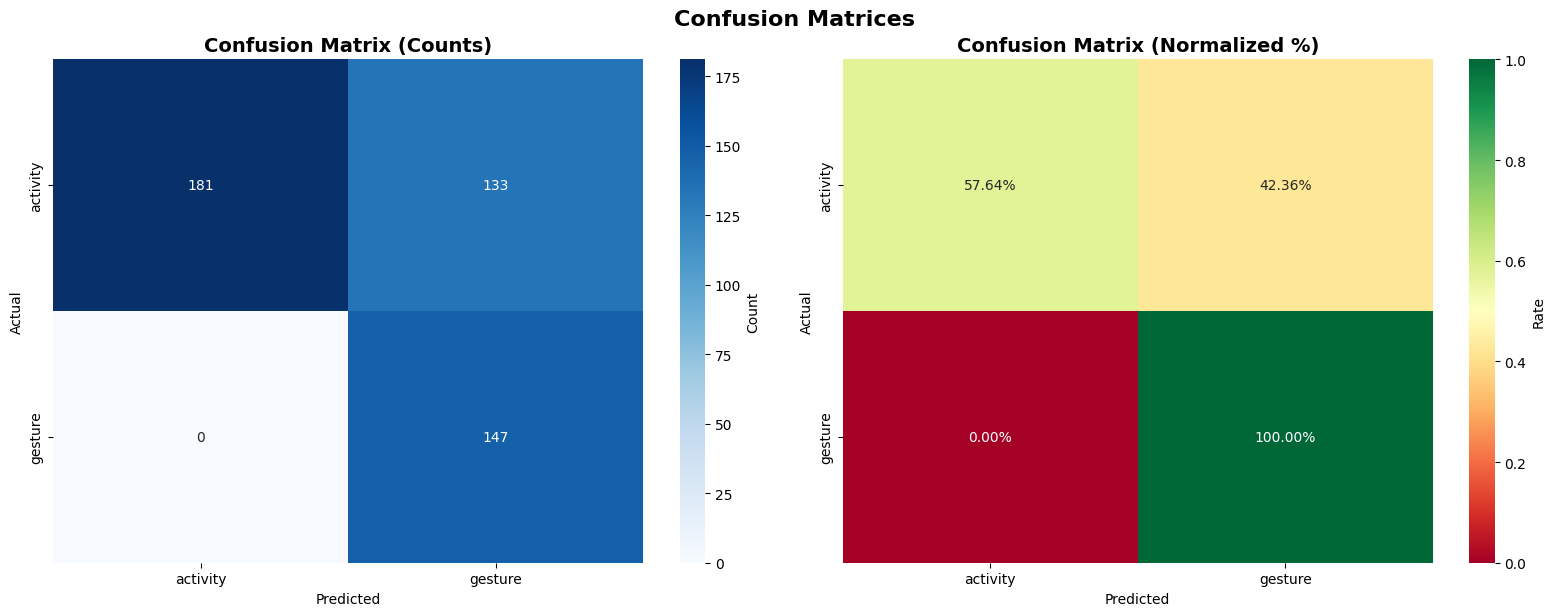

In [28]:
# ========== PLOT: Confusion Matrix ==========
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support
import seaborn as sns

# If seaborn not available, install it
try:
    import seaborn as sns
except ImportError:
    !pip install -q seaborn
    import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Normalized
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='RdYlGn', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1], vmin=0, vmax=1, cbar_kws={'label': 'Rate'})
axes[1].set_title('Confusion Matrix (Normalized %)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.suptitle('Confusion Matrices', fontsize=16, fontweight='bold', y=1.02)
plt.show()

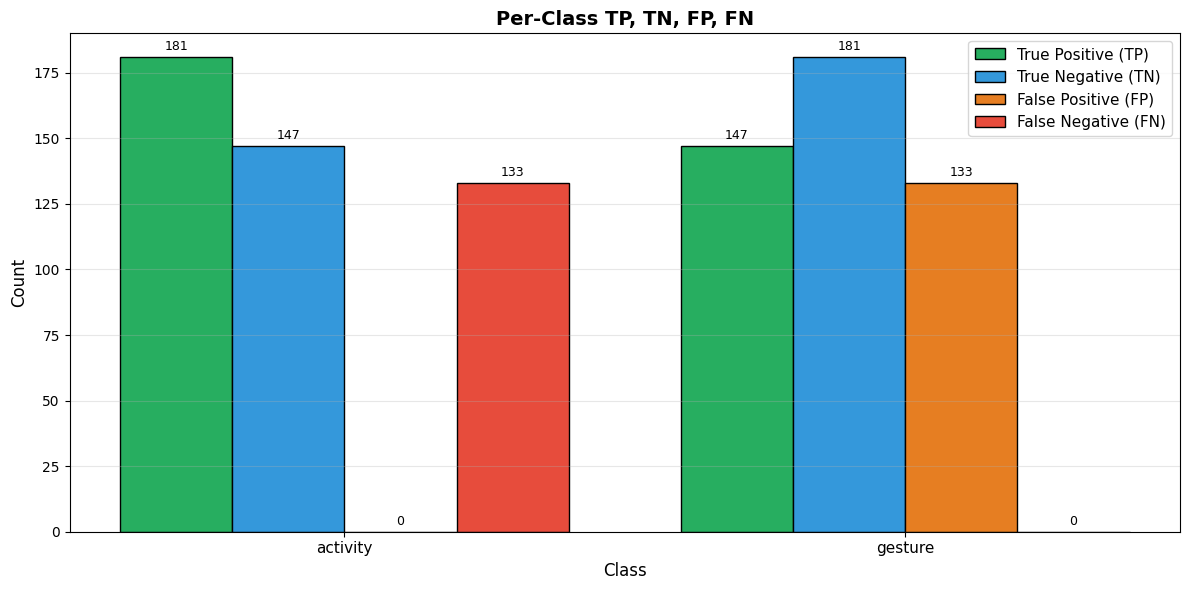

In [29]:
# ========== PLOT: Per-class TP, TN, FP, FN ==========
cm_full = confusion_matrix(y_true, y_pred)
n_classes = len(CLASS_NAMES)

tp_list, tn_list, fp_list, fn_list = [], [], [], []
for i in range(n_classes):
    tp = cm_full[i, i]
    fn = cm_full[i, :].sum() - tp
    fp = cm_full[:, i].sum() - tp
    tn = cm_full.sum() - tp - fn - fp
    tp_list.append(tp)
    tn_list.append(tn)
    fp_list.append(fp)
    fn_list.append(fn)

x = np.arange(n_classes)
width = 0.2

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - 1.5*width, tp_list, width, label='True Positive (TP)', color='#27ae60', edgecolor='black')
bars2 = ax.bar(x - 0.5*width, tn_list, width, label='True Negative (TN)', color='#3498db', edgecolor='black')
bars3 = ax.bar(x + 0.5*width, fp_list, width, label='False Positive (FP)', color='#e67e22', edgecolor='black')
bars4 = ax.bar(x + 1.5*width, fn_list, width, label='False Negative (FN)', color='#e74c3c', edgecolor='black')

ax.set_xlabel('Class', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Per-Class TP, TN, FP, FN', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

# Annotate bars
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

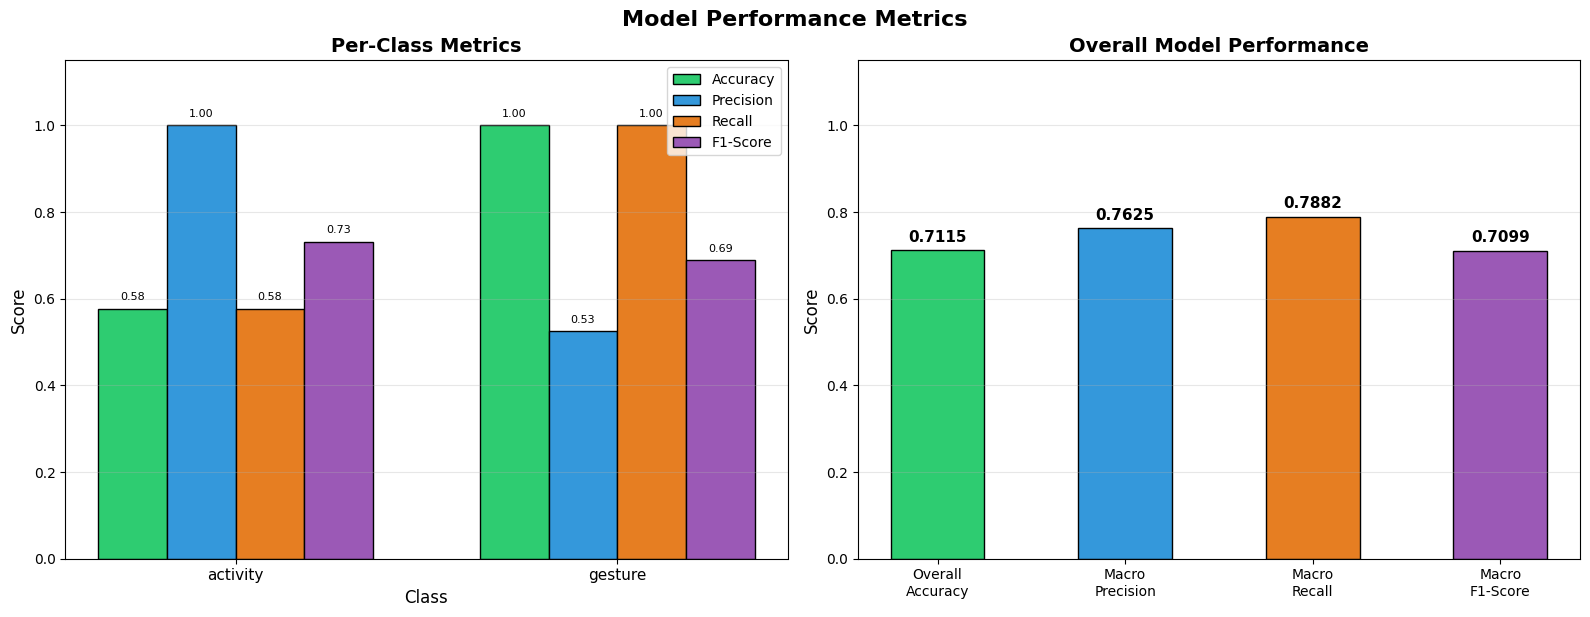

In [30]:
# ========== PLOT: Per-class Precision, Recall, F1-Score, Accuracy ==========
prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1])

# Per-class accuracy
per_class_acc = []
for i in range(n_classes):
    mask = y_true == i
    per_class_acc.append((y_pred[mask] == y_true[mask]).mean())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart of precision, recall, f1, accuracy per class
x = np.arange(n_classes)
width = 0.18
axes[0].bar(x - 1.5*width, per_class_acc, width, label='Accuracy', color='#2ecc71', edgecolor='black')
axes[0].bar(x - 0.5*width, prec, width, label='Precision', color='#3498db', edgecolor='black')
axes[0].bar(x + 0.5*width, rec, width, label='Recall', color='#e67e22', edgecolor='black')
axes[0].bar(x + 1.5*width, f1, width, label='F1-Score', color='#9b59b6', edgecolor='black')

axes[0].set_xlabel('Class', fontsize=12)
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_title('Per-Class Metrics', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(CLASS_NAMES, fontsize=11)
axes[0].legend(fontsize=10)
axes[0].set_ylim([0, 1.15])
axes[0].grid(True, alpha=0.3, axis='y')

# Add value annotations
for i, (a, p, r, f) in enumerate(zip(per_class_acc, prec, rec, f1)):
    axes[0].text(i - 1.5*width, a + 0.02, f'{a:.2f}', ha='center', fontsize=8)
    axes[0].text(i - 0.5*width, p + 0.02, f'{p:.2f}', ha='center', fontsize=8)
    axes[0].text(i + 0.5*width, r + 0.02, f'{r:.2f}', ha='center', fontsize=8)
    axes[0].text(i + 1.5*width, f + 0.02, f'{f:.2f}', ha='center', fontsize=8)

# Macro/Weighted summary
macro_prec = prec.mean()
macro_rec = rec.mean()
macro_f1 = f1.mean()
overall_acc = accuracy_score(y_true, y_pred)

summary_labels = ['Overall\nAccuracy', 'Macro\nPrecision', 'Macro\nRecall', 'Macro\nF1-Score']
summary_values = [overall_acc, macro_prec, macro_rec, macro_f1]
summary_colors = ['#2ecc71', '#3498db', '#e67e22', '#9b59b6']

bars = axes[1].bar(summary_labels, summary_values, color=summary_colors, edgecolor='black', width=0.5)
axes[1].set_title('Overall Model Performance', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Score', fontsize=12)
axes[1].set_ylim([0, 1.15])
axes[1].grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars, summary_values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.02, f'{val:.4f}',
                ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.suptitle('Model Performance Metrics', fontsize=16, fontweight='bold', y=1.02)
plt.show()

In [31]:
# ========== Classification Report (text) ==========
print('=' * 60)
print('FULL CLASSIFICATION REPORT')
print('=' * 60)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
print('=' * 60)
print(f'Overall Test Accuracy: {accuracy_score(y_true, y_pred):.4f}')
print(f'Total Test Samples: {len(y_true)}')
print(f'  Activity samples: {(y_true == 0).sum()}')
print(f'  Gesture  samples: {(y_true == 1).sum()}')
print('=' * 60)

FULL CLASSIFICATION REPORT
              precision    recall  f1-score   support

    activity     1.0000    0.5764    0.7313       314
     gesture     0.5250    1.0000    0.6885       147

    accuracy                         0.7115       461
   macro avg     0.7625    0.7882    0.7099       461
weighted avg     0.8485    0.7115    0.7177       461

Overall Test Accuracy: 0.7115
Total Test Samples: 461
  Activity samples: 314
  Gesture  samples: 147


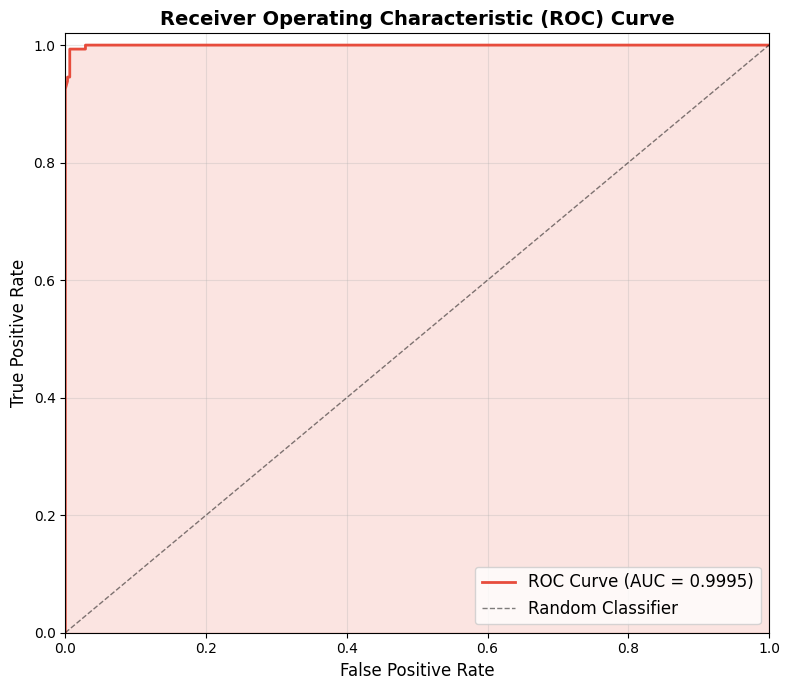

In [32]:
# ========== PLOT: ROC Curve ==========
from sklearn.metrics import roc_curve, auc

# Get prediction probabilities from the model
model_eval.eval()
all_probs = []
all_true_roc = []

class CSIDatasetSimple(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

test_dl_roc = DataLoader(CSIDatasetSimple(X_te_e, y_te_e), batch_size=BATCH_SIZE)

with torch.no_grad():
    for xb, yb in test_dl_roc:
        xb = xb.to(DEVICE)
        logits = model_eval(xb)
        probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        all_probs.extend(probs)
        all_true_roc.extend(yb.numpy())

all_probs = np.array(all_probs)
all_true_roc = np.array(all_true_roc)

fpr, tpr, thresholds = roc_curve(all_true_roc, all_probs)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(fpr, tpr, color='#e74c3c', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Random Classifier')
ax.fill_between(fpr, tpr, alpha=0.15, color='#e74c3c')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=12)
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.show()